In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

# Configure matplotlib to display plots inline directly inside the notebook
%matplotlib inline

In [2]:
def detect_bursts_autocorr(data, window_size, step_size, lag=50):
    """Slides a window across 1D data and computes the normalized autocorrelation at a specific lag."""
    num_windows = (len(data) - window_size) // step_size + 1
    detection_metric = np.zeros(num_windows)
    window_centers = np.zeros(num_windows)

    for i in range(num_windows):
        start = i * step_size
        end = start + window_size
        window_centers[i] = (start + end) / 2

        # Extract and mean-center local window segment
        segment = data[start:end]
        segment_norm = segment - np.mean(segment)

        if np.std(segment_norm) == 0: #skips empty segments
            continue

        # Compute autocorrelation at the target lag, lag: shift of the window to measure autocorrelation
        # Formula: R(lag) = sum( x[t] * x[t+lag] ) / sum( x[t]^2 )
        numerator = np.sum(segment_norm[:-lag] * segment_norm[lag:])
        denominator = np.sum(segment_norm**2)

        detection_metric[i] = (
            numerator / denominator if denominator > 0 else 0
        )

    return window_centers, detection_metric

In [3]:
# Set seed for reproducibility
np.random.seed(42)

fs = 1000  # Sampling frequency (Hz)
t = np.arange(0, 10, 1 / fs)  # Time vector (10 seconds)
signal = np.random.normal(0, 0.5, len(t))  # Baseline white noise floor

# Inject Burst 1: 20 Hz oscillation from sample index 2000 to 3500
burst1 = 1.5 * np.sin(2 * np.pi * 20 * t[2000:3500])
signal[2000:3500] += burst1

# Inject Burst 2: 20 Hz oscillation from sample index 6000 to 7500
burst2 = 1.5 * np.sin(2 * np.pi * 20 * t[6000:7500])
signal[6000:7500] += burst2

print(f"Generated signal with {len(signal)} samples.")


Generated signal with 10000 samples.


In [4]:
# Configuration Parameters
window_size = 500  # 0.5-second window size
step_size = 50  # 90% overlap for smooth transitions
target_lag = 50  # 50 samples = 0.05 seconds (matches the 20 Hz period: 1/20)
threshold = 0.25  # Correlation value cutoff for burst detection

# Run algorithm
centers, metric = detect_bursts_autocorr(
    signal, window_size, step_size, lag=target_lag
)

# Extract center indices of windows that passed thresholding
detected_indices = centers[metric > threshold].astype(int)
print(f"Algorithm flagged {len(detected_indices)} windows as containing bursts.")


Algorithm flagged 71 windows as containing bursts.


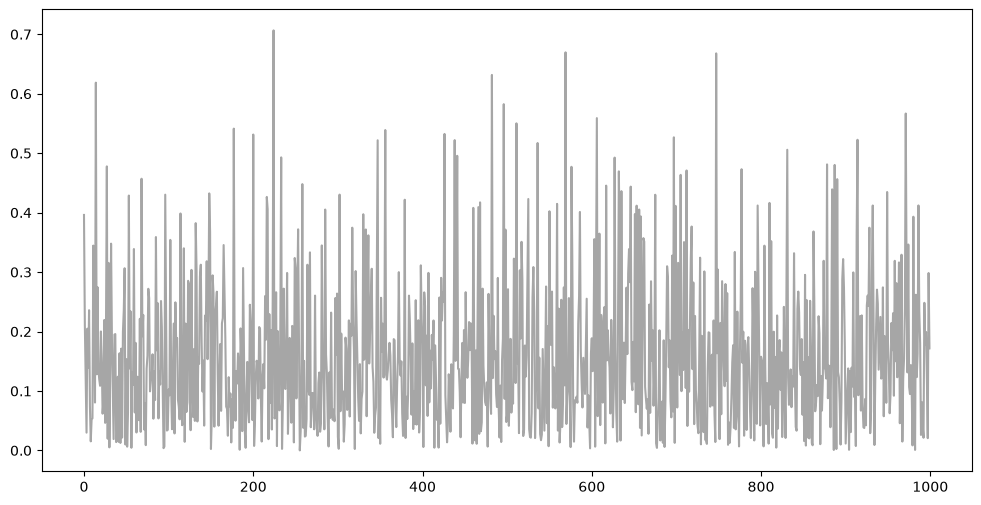

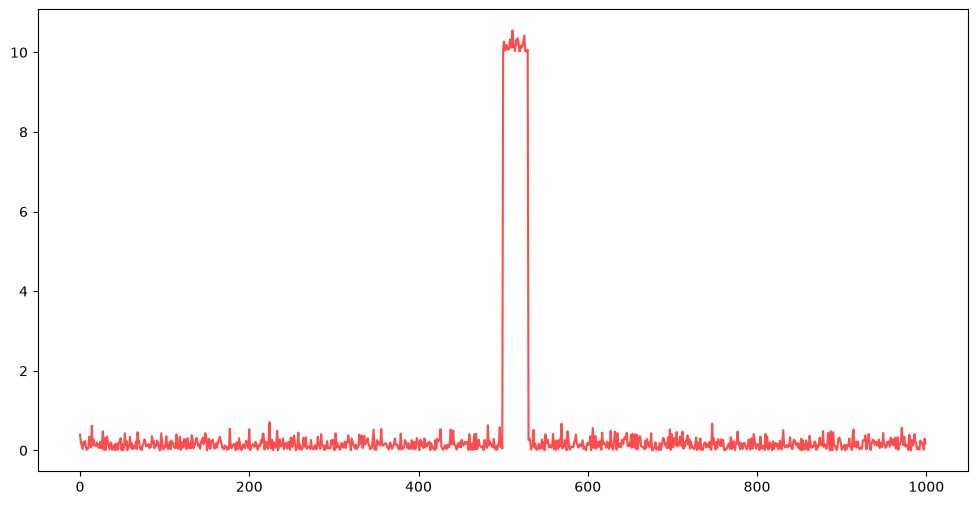

In [29]:
# modify the signal with something else
size = 1000
x = np.arange(0, size,1)
signal = np.abs(np.random.normal(0, 0.2, size))  # Baseline white noise floor

fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
ax1.plot(signal, label="Raw Signal", color="gray", alpha=0.7)

sig1_mod = 10*np.ones(30) #20.5 * np.abs(np.sin(2 * np.pi * 38.0 * x[500:620]))
signal[500:500 + len(sig1_mod)] += sig1_mod

fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
ax1.plot(signal, label="Raw Signal with inclusion", color="red", alpha=0.7)

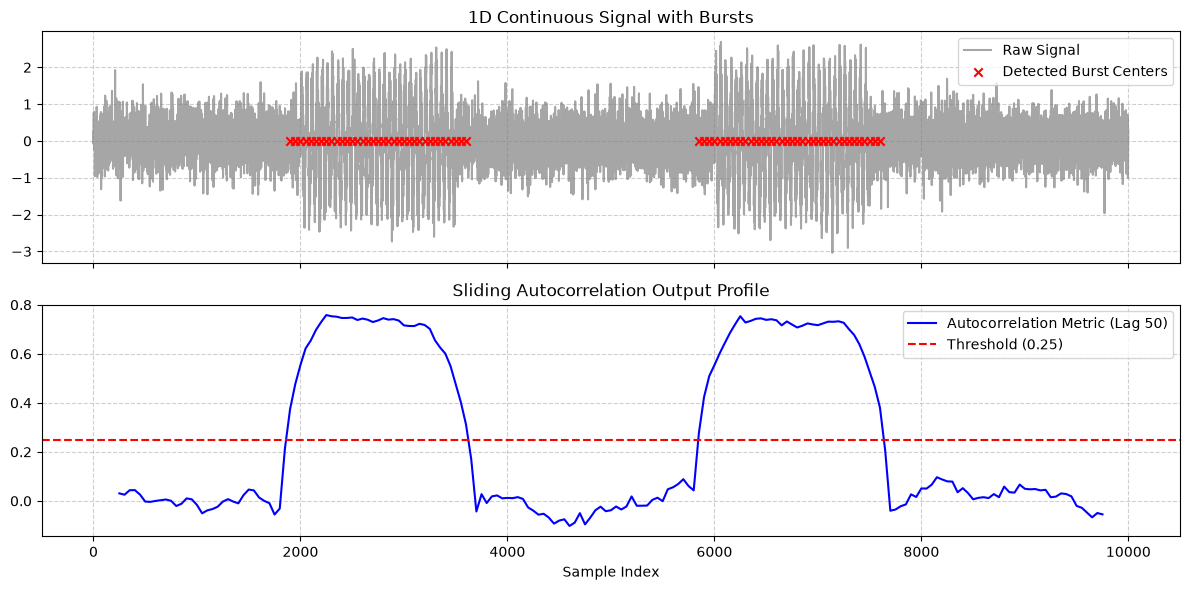

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# Top Plot: Raw Signal and Highlights
ax1.plot(signal, label="Raw Signal", color="gray", alpha=0.7)
if len(detected_indices) > 0:
    # Highlight detection zones across the entire x-axis sweep
    ax1.scatter(
        detected_indices,
        np.zeros_like(detected_indices),
        color="red",
        marker="x",
        label="Detected Burst Centers",
        zorder=3,
    )
ax1.set_title("1D Continuous Signal with Bursts")
ax1.legend(loc="upper right")
ax1.grid(True, linestyle="--", alpha=0.6)

# Bottom Plot: Autocorrelation Metric vs Threshold
ax2.plot(
    centers, metric, label=f"Autocorrelation Metric (Lag {target_lag})", color="blue"
)
ax2.axhline(
    y=threshold, color="red", linestyle="--", label=f"Threshold ({threshold})"
)
ax2.set_title("Sliding Autocorrelation Output Profile")
ax2.set_xlabel("Sample Index")
ax2.legend(loc="upper right")
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()
